In [259]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose
import keras
import tensorflow as tf

In [260]:
df = pd.read_csv('monthly_milk_production.csv', parse_dates=True, index_col='Date')

In [261]:
df.shape

(168, 1)

In [262]:
df.head()

,Production
Date,
1962-01-01,589
1962-02-01,561
1962-03-01,640
1962-04-01,656
1962-05-01,727


# **`1.	Exploratory Data Analysis (EDA)`**



**o	Visualize trends, seasonality, and anomalies in the milk production data.**

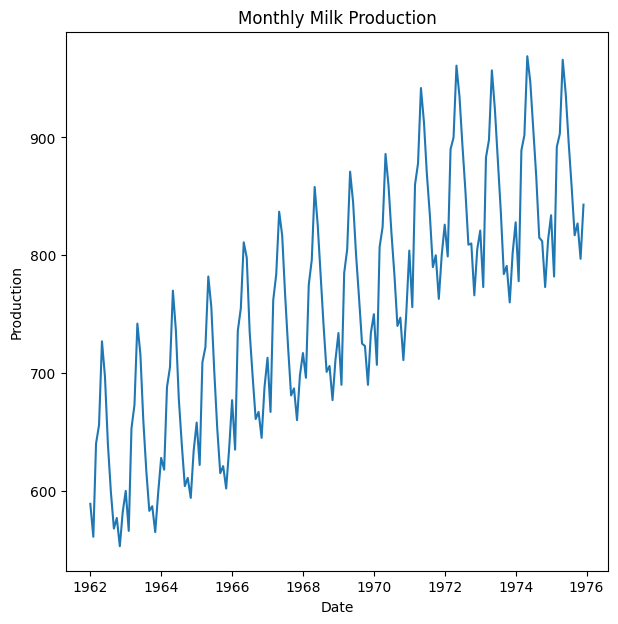

In [263]:
plt.figure(figsize=(7,7))
plt.plot(df)
plt.title('Monthly Milk Production')
plt.xlabel('Date')
plt.ylabel('Production')
plt.show()

In [264]:
result = seasonal_decompose(df['Production'], model='multiplicative', period=12)

Text(0.5, 1.0, 'Trend')

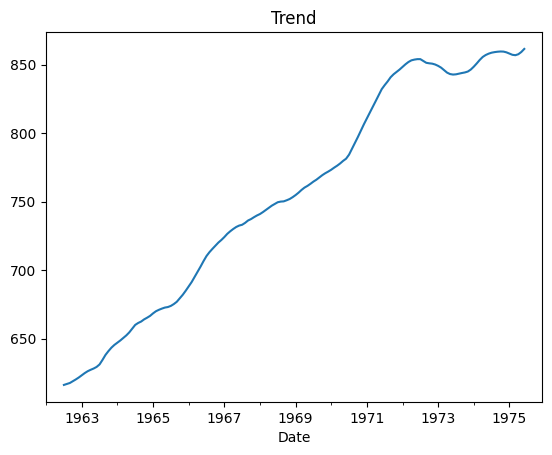

In [265]:
result.trend.plot()
plt.title('Trend')

Text(0.5, 1.0, 'Seasonality')

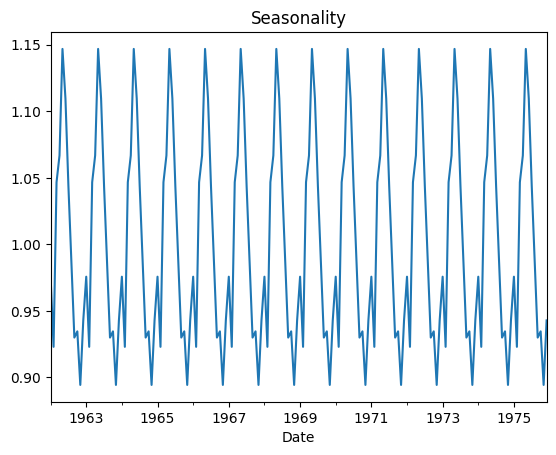

In [266]:
result.seasonal.plot()
plt.title('Seasonality')

Text(0.5, 1.0, 'Residuals')

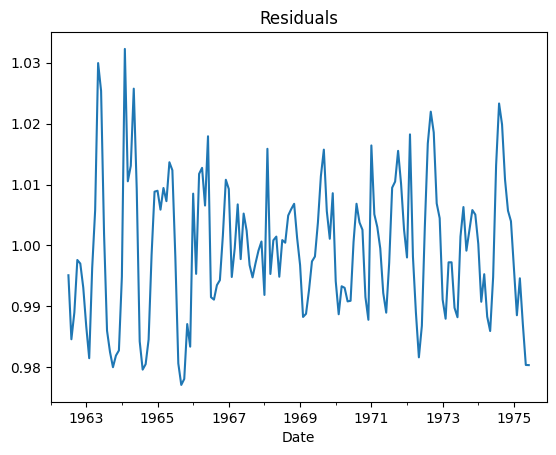

In [267]:
result.resid.plot()
plt.title('Residuals')

**o	Check for any missing values or outliers.**


In [268]:
#missing
df.isnull().sum()

,0
Production,0


In [269]:
#duplicates
df.duplicated().sum()

np.int64(26)

In [270]:
df = df.drop_duplicates()

In [271]:
df.duplicated().sum()

np.int64(0)

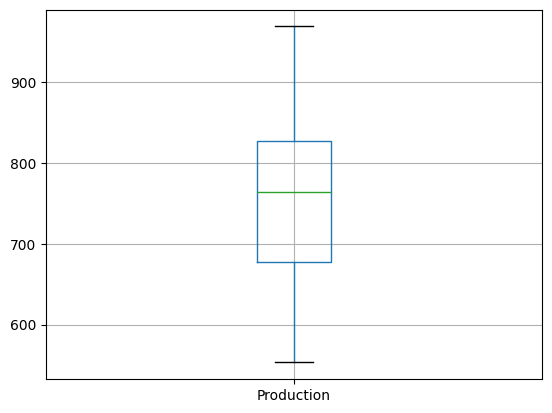

In [272]:
#outliers
df.boxplot()
plt.show()

**o	Normalize or scale the data for neural network models.**


In [273]:
min_sca = MinMaxScaler()
df[['Production']] = min_sca.fit_transform(df[['Production']])

In [274]:
df.head()

,Production
Date,
1962-01-01,0.086538
1962-02-01,0.019231
1962-03-01,0.209135
1962-04-01,0.247596
1962-05-01,0.418269


Explanation:
---

Loaded the dataset using pandas, parsed the Date column and set Date as index to treat it as a time-series dataset.

Visualization:

Plotted time-series line chart and performed seasonal decomposition.
Observed upward trend and clear yearly seasonality in milk production.

Data Checking:

Checked missing values, duplicates, and outliers.
No missing values found, duplicates removed, boxplot used for outlier inspection and no outliers was found.

Normalization:

Applied MinMax Scaling on Production column.
Scaled data between 0–1 for better deep learning model performance.

# **`2.	Data Preparation for Deep Learning`**


**o	Create input-output sequences (time windows) suitable for training RNNs/LSTMs/GRUs.**


In [275]:
data = df['Production'].values

In [276]:
#training data
#window_size = 12 (1 year)

x_train = [ ]
y_train = [ ]

for i in range(12, len(data)):
  x_train.append(data[i-12:i])
  y_train.append(data[i])

x_train = np.array(x_train)
y_train = np.array(y_train)

In [277]:
print(x_train.shape)
print(y_train.shape)

(130, 12)
(130,)


**o	Split data into training, validation, and test sets.**


In [278]:
x_all = x_train
y_all = y_train

In [279]:
total_samples = len(x_all)

In [280]:
train_size = int(0.7 * total_samples)
val_size = int(0.15 * total_samples)
test_size = total_samples - train_size - val_size

In [281]:
x_train = x_all[:train_size]
y_train = y_all[:train_size]

In [282]:
x_val = x_all[train_size:train_size + val_size]
y_val = y_all[train_size:train_size + val_size]

In [283]:
x_test = x_all[train_size + val_size:]
y_test = y_all[train_size + val_size:]

In [284]:
print("Train Shape:", x_train.shape, y_train.shape)
print("Validation Shape:", x_val.shape, y_val.shape)
print("Test Shape:", x_test.shape, y_test.shape)

Train Shape: (91, 12) (91,)
Validation Shape: (19, 12) (19,)
Test Shape: (20, 12) (20,)


**o	Reshape data for model input dimensions.**


In [285]:
x_train = x_train.reshape(x_train.shape[0], x_train.shape[1], 1)

In [286]:
x_train.shape

(91, 12, 1)

Explanation:
---

In this step, the production time-series data was converted into input-output sequences using a window size of 12 months (1 year), where the previous 12 values were used to predict the next value. The generated dataset was then split into 70% training (91 samples), 15% validation (19 samples), and 15% testing (20 samples) to ensure proper model learning and evaluation. After splitting, the input data was reshaped to 3D format (samples, time steps, features) → (91, 12, 1) so that it becomes suitable for RNN, LSTM, and GRU model architectures.

# **`3.	Model Building`**


**o	Build three separate models:**



Basic RNN:
---


In [287]:
#Model training

rnn = tf.keras.models.Sequential()
rnn.add(tf.keras.layers.SimpleRNN(units=20, return_sequences=True, input_shape=(12, 1)))
rnn.add(tf.keras.layers.Dropout(0.2))
rnn.add(tf.keras.layers.SimpleRNN(units=10, return_sequences=True))
rnn.add(tf.keras.layers.Dropout(0.2))
rnn.add(tf.keras.layers.Dense(1))

rnn.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_18 (SimpleRNN)       │ (None, 12, 20)         │           440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 12, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_19 (SimpleRNN)       │ (None, 12, 10)         │           310 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 12, 10)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 12, 1)          │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 761 (2.97 KB)

 Trainable params: 761 (2.97 KB)

 Non-trainable params: 0 (0.00 B)

In [288]:
#Model compile

rnn.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.mse)

In [289]:
#Model training and validation

history = rnn.fit(x_train, y_train, epochs=10, batch_size=5, validation_data=(x_val, y_val))

Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 0.3299 - val_loss: 0.0708
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1903 - val_loss: 0.0595
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1389 - val_loss: 0.0646
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1162 - val_loss: 0.0678
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0968 - val_loss: 0.0682
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0984 - val_loss: 0.0692
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0853 - val_loss: 0.0991
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0715 - val_loss: 0.0679
Epoch 9/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0709 - val_loss: 0.0993
Epoch 10/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0794 - val_loss: 0.0833


In [290]:
#prediction

pred = rnn.predict(x_test)
pred = pred[:, -1, :] #takes last timestep only to match dimension(2D)
y_pred_rnn = min_sca.inverse_transform(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step


LSTM:
---


In [291]:
#Model training

lstm = tf.keras.models.Sequential()
lstm.add(tf.keras.layers.LSTM(units=20, return_sequences=True, input_shape=(12, 1)))
lstm.add(tf.keras.layers.Dropout(0.2))
lstm.add(tf.keras.layers.LSTM(units=10, return_sequences=True))
lstm.add(tf.keras.layers.Dropout(0.2))
lstm.add(tf.keras.layers.Dense(1))

lstm.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 12, 20)         │         1,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 12, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 12, 10)         │         1,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 12, 10)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 12, 1)          │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,011 (11.76 KB)

 Trainable params: 3,011 (11.76 KB)

 Non-trainable params: 0 (0.00 B)

In [292]:
#Model compile

lstm.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.mse)

In [293]:
#Model training and validation

history = lstm.fit(x_train, y_train, epochs=10, batch_size=5, validation_data=(x_val, y_val))

Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.1618 - val_loss: 0.1902
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0838 - val_loss: 0.1369
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0788 - val_loss: 0.1420
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0743 - val_loss: 0.1259
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0644 - val_loss: 0.1261
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0659 - val_loss: 0.1128
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0725 - val_loss: 0.1253
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0560 - val_loss: 0.1168
Epoch 9/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0603 - val_loss: 0.1118
Epoch 10/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0566 - val_loss: 0.1163


In [294]:
#prediction

pred = lstm.predict(x_test)
pred = pred[:, -1, :] #takes last timestep only to match dimension(2D)
y_pred_lstm = min_sca.inverse_transform(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step


GRU:
---

In [295]:
#Model training

gru = tf.keras.models.Sequential()
gru.add(tf.keras.layers.GRU(units=20, return_sequences=True, input_shape=(12, 1)))
gru.add(tf.keras.layers.Dropout(0.2))
gru.add(tf.keras.layers.GRU(units=10, return_sequences=True))
gru.add(tf.keras.layers.Dropout(0.2))
gru.add(tf.keras.layers.Dense(1))

gru.summary()

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_6 (GRU)                     │ (None, 12, 20)         │         1,380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 12, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_7 (GRU)                     │ (None, 12, 10)         │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 12, 10)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 12, 1)          │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,351 (9.18 KB)

 Trainable params: 2,351 (9.18 KB)

 Non-trainable params: 0 (0.00 B)

In [296]:
#Model compile

gru.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.mse)

In [297]:
#Model training and validation

history = gru.fit(x_train, y_train, epochs=10, batch_size=5, validation_data=(x_val, y_val))

Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - loss: 0.1793 - val_loss: 0.1098
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0581 - val_loss: 0.0777
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0693 - val_loss: 0.1159
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0588 - val_loss: 0.0892
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0615 - val_loss: 0.1060
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0494 - val_loss: 0.1164
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0586 - val_loss: 0.0952
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0636 - val_loss: 0.1131
Epoch 9/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0471 - val_loss: 0.1045
Epoch 10/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0527 - val_loss: 0.1046


In [298]:
#prediction

pred = gru.predict(x_test)
pred = pred[:, -1, :] #takes last timestep only to match dimension(2D)
y_pred_gru = min_sca.inverse_transform(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step


**o	Tune hyperparameters (e.g., window size, number of units, batch size, epochs).**


In [299]:
#training data
#window_size = 24 (2 year)

x_train1 = [ ]
y_train1 = [ ]

for i in range(24, len(data)):
  x_train1.append(data[i-24:i])
  y_train1.append(data[i])

x_train1 = np.array(x_train1)
y_train1 = np.array(y_train1)

In [300]:
#splittting
total_samples1 = len(x_train1)

In [301]:
train_size1 = int(0.7 * total_samples1)
val_size1 = int(0.15 * total_samples1)
test_size1 = total_samples1 - train_size1 - val_size1

In [302]:
x_train_1 = x_train1[:train_size1]
y_train_1 = y_train1[:train_size1]

In [303]:
x_val_1 = x_train1[train_size1:train_size1 + val_size1]
y_val_1 = y_train1[train_size1:train_size1 + val_size1]

In [304]:
x_test_1 = x_train1[train_size1 + val_size1:]
y_test_1 = y_train1[train_size1 + val_size1:]

In [305]:
#window_size = 24
#numbers of units = 30, 15, 1
#batch size = 10
#epochs = 20

#Model training

rnn1 = tf.keras.models.Sequential()
rnn1.add(tf.keras.layers.SimpleRNN(units=30, return_sequences=True, input_shape=(24, 1)))
rnn1.add(tf.keras.layers.Dropout(0.2))
rnn1.add(tf.keras.layers.SimpleRNN(units=15, return_sequences=True))
rnn1.add(tf.keras.layers.Dropout(0.2))
rnn1.add(tf.keras.layers.Dense(1))

rnn1.summary()

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_20 (SimpleRNN)       │ (None, 24, 30)         │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 24, 30)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_21 (SimpleRNN)       │ (None, 24, 15)         │           690 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 24, 15)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 24, 1)          │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,666 (6.51 KB)

 Trainable params: 1,666 (6.51 KB)

 Non-trainable params: 0 (0.00 B)

In [306]:
#Model compile

rnn1.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.mse)

In [307]:
#Model training and validation

history = rnn1.fit(x_train_1, y_train_1, epochs=20, batch_size=10, validation_data=(x_val, y_val))

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - loss: 1.2647 - val_loss: 0.7973
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.3313 - val_loss: 0.2615
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.2424 - val_loss: 0.2002
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.2182 - val_loss: 0.1767
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1927 - val_loss: 0.1725
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1580 - val_loss: 0.1711
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1504 - val_loss: 0.1599
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1283 - val_loss: 0.1609
Epoch 9/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1231 - val_loss: 0.1550
Epoch 10/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1180 - val_loss: 0.1482
Epoch 11/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1076 - val_loss: 0.1352
Epoch 12/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1051 - val_loss: 0.1236
E

In [308]:
#prediction

y_pred_rnn1 = rnn1.predict(x_test_1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step


In [309]:
rnn1.evaluate(x_test_1, y_test_1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - loss: 0.0937


0.09374258667230606

**o	Use appropriate loss functions and optimizers.**


Mean Squared Error (MSE) was used as the loss function since the problem is a time-series forecasting task. Adam optimizer was selected because it provides faster convergence and adaptive learning rates for better model performance.”

Explanation:
---

Three deep learning models — Basic RNN, LSTM, and GRU — were built using TensorFlow Sequential API for time-series forecasting. For each of the three models, model building, compilation, training and validation, prediction were performed separately to compare their performance. The input shape was defined from the reshaped training data, and dropout layers were added to reduce overfitting. All models were compiled using the Adam optimizer and Mean Squared Error (MSE) loss function.

For hyperparameter tuning, different values of window size(24), number of units(30, 15, 1), epochs(20), and batch size(10) were experimented. While tuning, separate variable names were used to avoid confusion — x_train1 was used for tuned model training data, whereas x_train_1 was used during the splitting stage. This distinction helped in clearly managing the original dataset and the modified tuned dataset.And Model predictions were generated on the test data.
The model was evaluated on the test dataset to measure its final performance loss.

# **`4.	Model Evaluation`**


**o	Plot predictions vs. actual values.**


In [310]:
y_test_org = min_sca.inverse_transform(y_test.reshape(-1, 1))

Basic RNN:
---

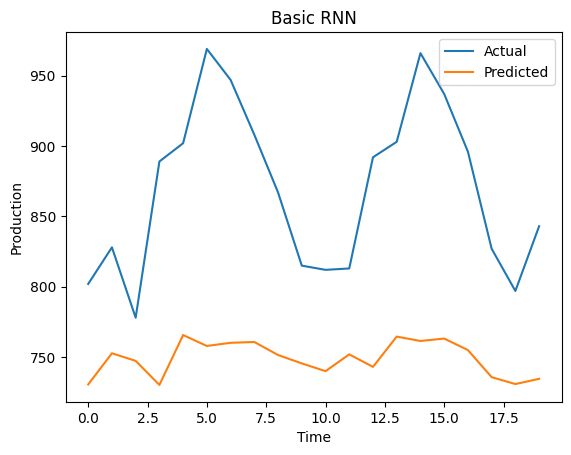

In [311]:
plt.plot(y_test_org, label='Actual')
plt.plot(y_pred_rnn, label='Predicted')
plt.title('Basic RNN')
plt.xlabel('Time')
plt.ylabel('Production')
plt.legend()
plt.show()

LSTM:
---

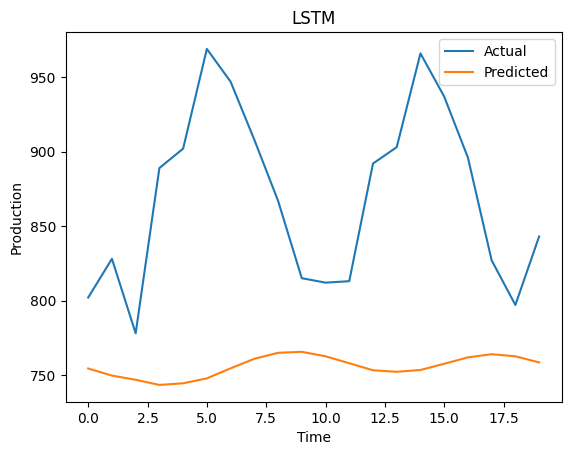

In [312]:
plt.plot(y_test_org, label='Actual')
plt.plot(y_pred_lstm, label='Predicted')
plt.xlabel('Time')
plt.ylabel('Production')
plt.title('LSTM')
plt.legend()
plt.show()

GRU:
---

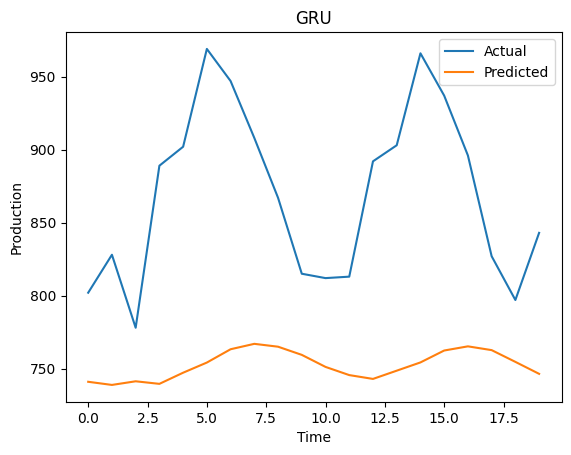

In [313]:
plt.plot(y_test_org, label='Actual')
plt.plot(y_pred_gru, label='Predicted')
plt.title('GRU')
plt.xlabel('Time')
plt.ylabel('Production')
plt.legend()
plt.show()

**o	Calculate forecasting metrics: RMSE, MAE, MAPE.**


In [314]:
def evaluate_model(y_true, y_pred):
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    return rmse, mae, mape

In [315]:
#rnn metrics

rnn_rmse, rnn_mae, rnn_mape = evaluate_model(y_test_org, y_pred_rnn)

In [316]:
#lstm metrics

lstm_rmse, lstm_mae, lstm_mape = evaluate_model(y_test_org, y_pred_lstm)

In [317]:
#gru metrics

gru_rmse, gru_mae, gru_mape = evaluate_model(y_test_org, y_pred_gru)

In [318]:
results = pd.DataFrame({
    'Model': ['Basic RNN', 'LSTM', 'GRU'],
    'RMSE': [rnn_rmse, lstm_rmse, gru_rmse],
    'MAE': [rnn_mae, lstm_mae, gru_mae],
    'MAPE': [rnn_mae, lstm_mape, gru_mape]
})

In [319]:
results = results.set_index('Model')

In [320]:
results = results.round(2)

In [321]:
print(results)

             RMSE     MAE    MAPE
Model                            
Basic RNN  130.67  120.42  120.42
LSTM       128.71  113.80    0.13
GRU        129.34  117.02    0.13


**o	Compare the performance of RNN, LSTM, and GRU.**


Among the three models, LSTM performed the best as it achieved the lowest RMSE, MAE, and MAPE values, indicating higher prediction accuracy. GRU showed the highest error values, while Basic RNN performed moderately in comparison.

Explanation:
---

In this, the trained Basic RNN, LSTM, and GRU models were evaluated using both visual and numerical methods. First, the scaled test values were converted back to original production values using inverse MinMax scaling (y_test_org) so that predictions and actual values could be compared in real-world units. Then, prediction vs actual line graphs were plotted separately for each model to visually analyze how closely the models followed the true trend.

After visualization, forecasting performance metrics such as RMSE, MAE, and MAPE were calculated for all three models. These metric values were organized into a comparison table to clearly identify which model performed better. This combined approach of graphs and metrics helped in understanding both the accuracy and error levels of each model effectively. Among all LSTM performed best.

# **`5.	Prediction and Visualization`**


**o	Forecast milk production for the next 12 months.**


In [322]:
forecast = lstm.predict(x_test[-12:])
forecast = forecast[:, -1, :]
forecast_org = min_sca.inverse_transform(forecast)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step


**o	Visualize the predicted trend with uncertainty or confidence intervals if possible.**


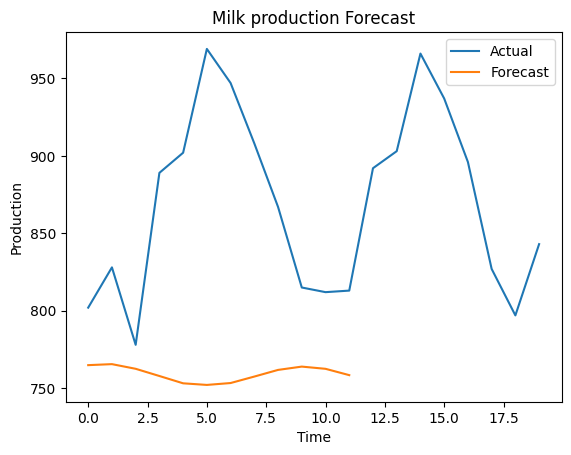

In [323]:
plt.plot(y_test_org, label='Actual')
plt.plot(forecast_org, label='Forecast')

plt.title('Milk production Forecast')
plt.xlabel('Time')
plt.ylabel('Production')
plt.legend()
plt.show()

Explanation:
---

In this step, the trained LSTM model was used to forecast milk production for the next 12 months using the last available test sequences. The predicted values were then converted back to original scale using inverse transformation so that the results match the real production units.

After forecasting, a line plot was created to visually compare the actual production values and the forecasted values. This visualization helps in understanding the future trend of milk production and shows how the model expects the production to change over time.

Although confidence intervals were not added, the graph clearly illustrates the expected upward and downward seasonal pattern, which is useful for planning and analysis.

# **`6.	Business Insights`**


**o	Interpret results and recommend how the dairy business can use these forecasts for better planning and resource allocation.**

From the forecasting results, it is observed that milk production follows a seasonal pattern with periodic increases and decreases. Among the three models, LSTM provided more accurate predictions, making it more reliable for future planning.

These forecasts can help dairy businesses in production planning, inventory management, and resource allocation such as workforce, storage, and transportation. By anticipating high-production months, the business can prepare sufficient storage and distribution facilities, and during low-production periods, they can optimize costs and reduce wastage. Overall, the forecasting model supports better decision-making and efficient operational planning.